# PINN / MLP Project: Training Choices for a 2D Cantilever Deep Energy Method

## Overview
The PINN lecture slides by Professor Krishna Kumar solve a linear elastic 2D cantilever beam by energy minimization, with strong boundary condition (BC) enforcement through trial functions. This notebook studies how training choices affect accuracy. I vary the learning rate, the optimizer, the number of collocation points, and adding adaptive weights with a soft BC enforcement.

**Goal:** find which approach gives the lowest error and beat the baseline relative L2 error of $2.4 \times 10^{-3}$.

**Benchmarks:** every case is compared against (1) the closed-form solution and (2) the baseline solution from the course slides.

## Problem Setup
All cases use the problem in Figure 1 of the course slides.

| Parameter | Value |
|---|---|
| Length, $L$ | 8 |
| Height, $W$ | 2 |
| Young's modulus, $E$ | $1 \times 10^3$ |
| Poisson's ratio, $\nu$ | 0.25 |
| End load, $P$ | 2 |

<div align="center">
  <img src="BeamProblem.png" alt="Description" width="800px">
  <p><b>Figure 1:</b> Problem Setup.</p>
</div>

**Governing approach:** the network $\mathbf{u}_\theta(x, y)$ approximates the displacement field. Training minimizes the total potential energy

$$
\Pi(\theta) = \int_\Omega \psi(\boldsymbol{\varepsilon}(\mathbf{u}_\theta)) \, d\Omega - \int_{\Gamma_t} \mathbf{t} \cdot \mathbf{u}_\theta \, d\Gamma
$$

where $\psi$ is the linear elastic strain energy density and the integrals are evaluated at the collocation points.

**Baseline configuration (course slides):**
- Architecture: MLP $[2, 20, 20, 20, 20, 2]$, tanh activation
- BC enforcement: hard (strong), through trial functions
- Optimizer: Adam, learning rate $1 \times 10^{-4}$, 15,000 epochs
- Collocation grid: (80, 40)
- Relative L2 error: $2.4 \times 10^{-3}$

In [1]:
%reset

Nothing done.


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

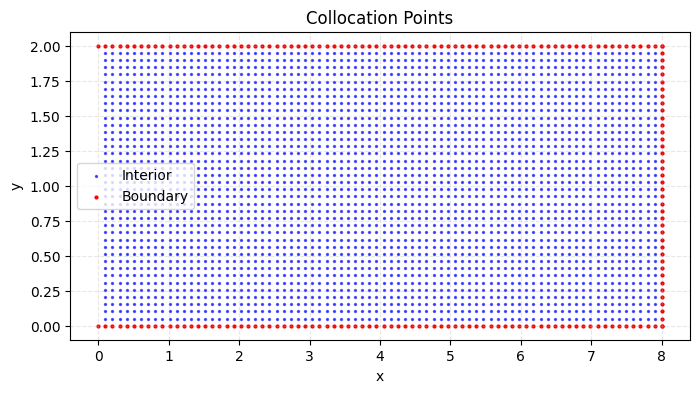

In [3]:
# Set default tensor type and device
torch.set_default_dtype(torch.float64)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Check if MPS is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')    

# Material and geometric parameters
E = 1e3           # Young's modulus
nu = 0.25         # Poisson's ratio
P = 2.0           # Applied load
L = 8.0           # Length of the beam
W = 2.0           # Width of the beam
b = 1.0           # Depth of the beam
I = b * W**3 / 12.0   # Moment of inertia
lambda_ = E * nu / ((1 + nu)*(1 - 2*nu))  # Lamé's first parameter
mu = E / (2*(1 + nu))  # Lamé's second parameter (shear modulus)

# Generate interior collocation points (excluding x=0)
Nx, Ny = 80, 40  # Original grid size
x = np.linspace(0, L, Nx)[1:]  # Exclude x=0 point
y = np.linspace(0, W, Ny)[1:-1]  # Exclude top and bottom boundaries
X, Y = np.meshgrid(x, y)
X_star = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

# Generate boundary points
# Right boundary (x = L)
y_right = np.linspace(0, W, Ny)
x_right = L * np.ones_like(y_right)
X_right = np.hstack((x_right[:, None], y_right[:, None]))

# Top boundary (y = W/2)
x_top = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
y_top = (W) * np.ones_like(x_top)
X_top = np.hstack((x_top[:, None], y_top[:, None]))

# Bottom boundary (y = -W/2)
x_bottom = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
y_bottom =  0 * np.ones_like(x_bottom) #(-W/2)
X_bottom = np.hstack((x_bottom[:, None], y_bottom[:, None]))

# Combine all boundary points
X_boundary = np.vstack((X_right, X_top, X_bottom))

# Convert to torch tensors
x_collocation = torch.tensor(X_star[:, 0:1], requires_grad=True, device=device)
y_collocation = torch.tensor(X_star[:, 1:2], requires_grad=True, device=device)

x_boundary_tensor = torch.tensor(X_boundary[:, 0:1], requires_grad=True, device=device)
y_boundary_tensor = torch.tensor(X_boundary[:, 1:2], requires_grad=True, device=device)

# Plot collocation points
plt.figure(figsize=(8, 4))

# Interior points (blue)
plt.scatter(X_star[:, 0], X_star[:, 1], c='blue', s=2, alpha=0.6, label='Interior')

# Boundary points (red)
plt.scatter(X_boundary[:, 0], X_boundary[:, 1], c='red', s=4, label='Boundary')

plt.title('Collocation Points')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [4]:
# Defomote PINN
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        hdim = 20
        self.layers = nn.Sequential(
            nn.Linear(2, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, 2)
        )

    def forward(self, x, y):
        inputs = torch.cat((x, y), dim=1)
        # inputs = torch.tanh(inputs)
        outputs = self.layers(inputs)
        return outputs[:, 0:1], outputs[:, 1:2]


# Initialize model and move to device
model = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

In [5]:
def linear_distance(x, L):
    """Current simple linear distance function"""
    return x/L

def polynomial_distance(x, L, n=3):
    """Polynomial distance function
    n: polynomial degree (odd number)"""
    return (x/L)**n * (1 - (x/L))**(n-1) + x/L

# The correct strong form enforcement
def net_u(model, x, y):
    u_NN, _ = model(x, y)
    # Analytical solution at x=0
    g_u = (P * y) / (6 * E * I) * ((2 + nu) * (y**2 - W**2/4))
    return g_u + polynomial_distance(x, L) * u_NN

def net_v(model, x, y):
    _, v_NN = model(x, y)
    # Analytical solution at x=0
    g_v = -(P) / (6 * E * I) * (3 * nu * y**2 * L)
    return g_v + polynomial_distance(x, L) * v_NN

def strain(model, x, y):
    u = net_u(model, x, y)
    v = net_v(model, x, y)

    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                             create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u),
                             create_graph=True)[0]
    v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v),
                             create_graph=True)[0]
    v_y = torch.autograd.grad(v, y, grad_outputs=torch.ones_like(v),
                             create_graph=True)[0]

    epsilon_xx = u_x
    epsilon_yy = v_y
    epsilon_xy = 0.5 * (u_y + v_x)

    return epsilon_xx, epsilon_yy, epsilon_xy

def stress(model, x, y):
    epsilon_xx, epsilon_yy, epsilon_xy = strain(model, x, y)

    sigma_xx = lambda_ * (epsilon_xx + epsilon_yy) + 2 * mu * epsilon_xx
    sigma_yy = lambda_ * (epsilon_xx + epsilon_yy) + 2 * mu * epsilon_yy
    sigma_xy = 2 * mu * epsilon_xy

    return sigma_xx, sigma_yy, sigma_xy

def traction_x(y):
    return torch.zeros_like(y)

def traction_y(y):
    return P * (y**2 - y * W) / (2 * I)

def potential_energy(model):
    # Get strains and stresses at collocation points
    epsilon_xx, epsilon_yy, epsilon_xy = strain(model, x_collocation, y_collocation)
    
    # Compute strain energy density
    # First term: λ(εxx + εyy)^2
    psi_1 = 0.5 * lambda_ * (epsilon_xx + epsilon_yy)**2
    
    # Second term: μ(εxx^2 + εyy^2 + 2εxy^2)
    psi_2 = mu * (epsilon_xx**2 + epsilon_yy**2 + 2 * epsilon_xy**2)
    
    # Total strain energy density
    strain_energy_density = psi_1 + psi_2
    
    # Numerical integration over domain
    dx = L / (Nx - 2)  # Adjusted for excluding x=0
    dy = W / (Ny - 2)  # Adjusted for excluding boundaries
    area_element = dx * dy
    
    # Internal energy = ∫∫ Ψ dxdy
    internal_energy = (strain_energy_density * area_element).sum()
    
    # External work from traction on right boundary
    # Get displacements on right boundary
    u_right = net_u(model, x_boundary_tensor[:Ny], y_boundary_tensor[:Ny])
    v_right = net_v(model, x_boundary_tensor[:Ny], y_boundary_tensor[:Ny])
    
    # Traction components on right boundary
    t_x_right = torch.zeros_like(y_boundary_tensor[:Ny])
    t_y_right = P * (y_boundary_tensor[:Ny]**2 - y_boundary_tensor[:Ny] * W) / (2 * I)
    
    # External work = -∫ t·u dΓ
    external_work = ((t_x_right * u_right + t_y_right * v_right) * (W/(Ny-1))).sum()
    
    # Total potential energy = Internal + External
    total_energy = internal_energy + external_work
    
    return total_energy

# Training loop
def closure(model):
    optimizer.zero_grad()
    energy = potential_energy(model)
    energy.backward()
    return energy

print("Initial energy:", potential_energy(model).item())

# First train with Adam
optimizer = optim.Adam(model.parameters(), lr=1e-4)

num_epochs = 15000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model)
    energy.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}')
        
print("energy:", potential_energy(model).item())

Initial energy: 351.204292649702
Epoch [0/15000], Energy: 351.204293
Epoch [1000/15000], Energy: 0.510930
Epoch [2000/15000], Energy: 0.112625
Epoch [3000/15000], Energy: -0.077331
Epoch [4000/15000], Energy: -0.228140
Epoch [5000/15000], Energy: -0.327020
Epoch [6000/15000], Energy: -0.370402
Epoch [7000/15000], Energy: -0.392835
Epoch [8000/15000], Energy: -0.410193
Epoch [9000/15000], Energy: -0.424477
Epoch [10000/15000], Energy: -0.433261
Epoch [11000/15000], Energy: -0.438502
Epoch [12000/15000], Energy: -0.443769
Epoch [13000/15000], Energy: -0.450155
Epoch [14000/15000], Energy: -0.457119
energy: -0.4646480869017824


In [6]:
# Testing the model
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred = net_u(model, x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred = net_v(model, x_test_tensor, y_test_tensor).cpu().detach().numpy()

def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u = np.linalg.norm(u_exact_val - u_pred, 2) / np.linalg.norm(u_exact_val, 2)
error_v = np.linalg.norm(v_exact_val - v_pred, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u: {error_u:e}')
print(f'Relative L2 error in v: {error_v:e}')

Relative L2 error in u: 5.950423e-02
Relative L2 error in v: 2.633966e-02


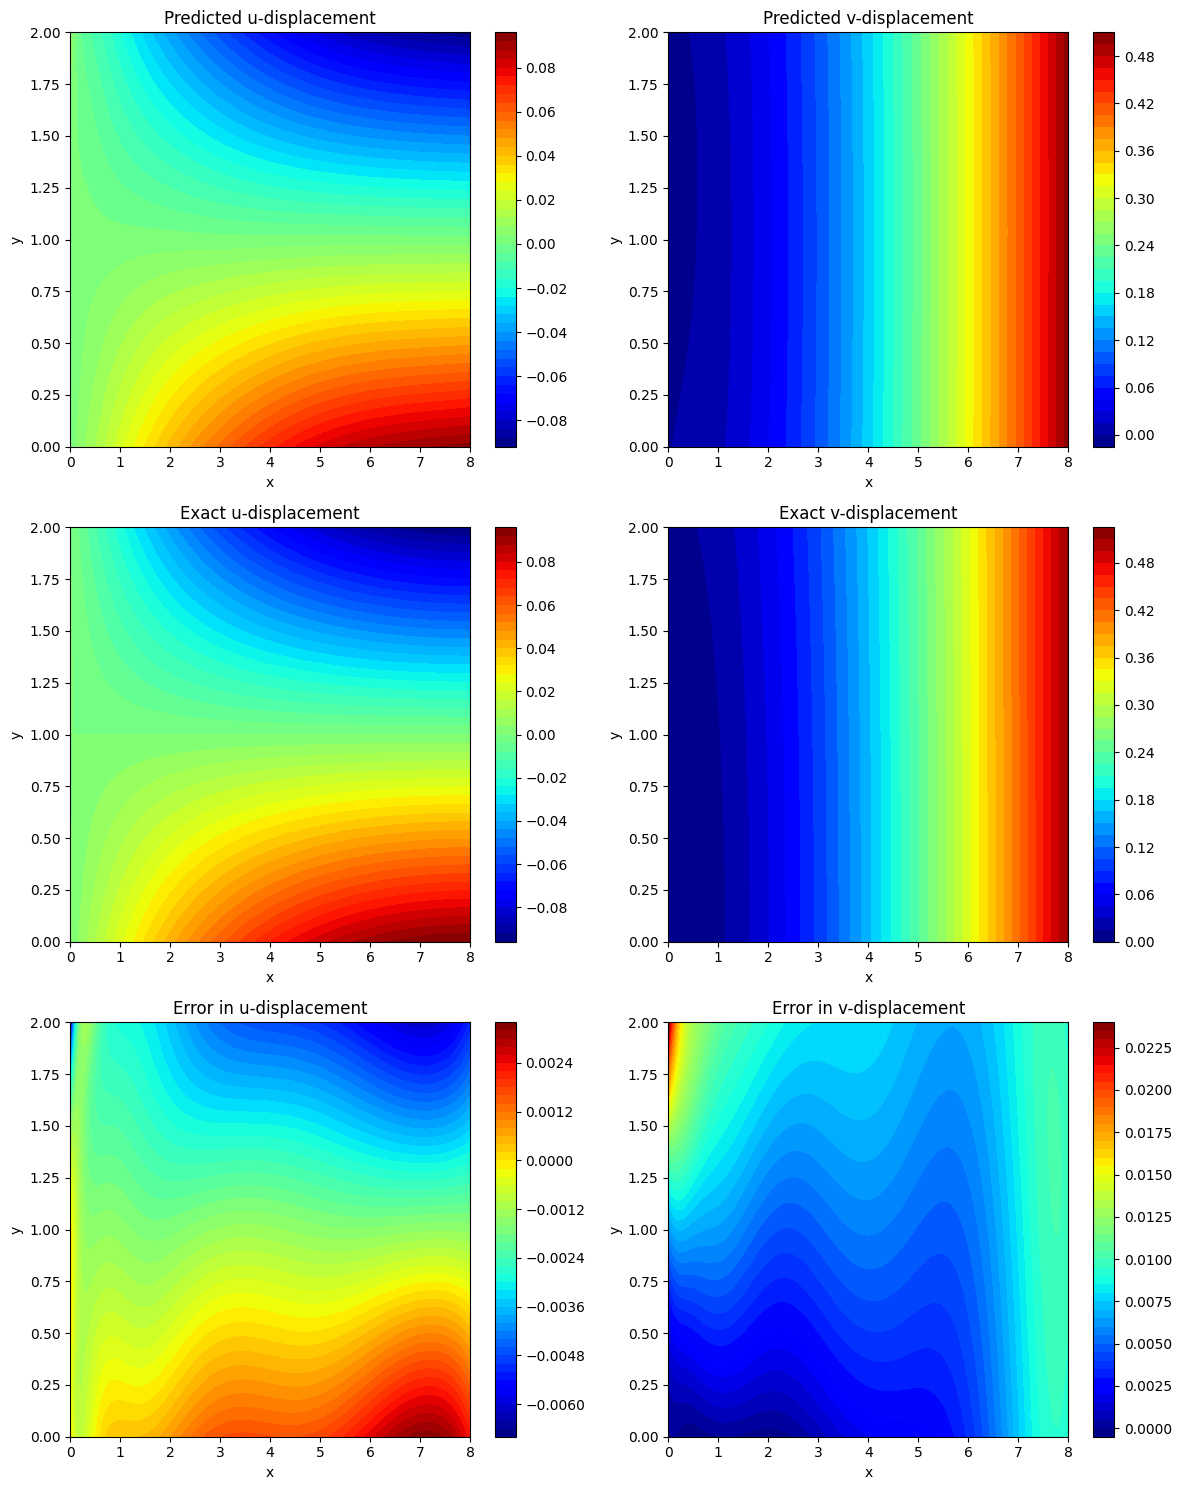

In [7]:
# Reshape data for plotting
U_pred = u_pred.reshape(2*Ny, 2*Nx)
V_pred = v_pred.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)
Error_U = (U_exact - U_pred)
Error_V = (V_exact - V_pred)

# Plotting the results
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

## Error Metric and Benchmarks
The relative L2 error is computed against the closed-form solution:

$$
\epsilon_{L2} = \frac{\lVert \mathbf{u}_\theta - \mathbf{u}_{\text{exact}} \rVert_2}{\lVert \mathbf{u}_{\text{exact}} \rVert_2}
$$

Every case reports:
1. Relative L2 error vs. the closed-form solution
2. Relative L2 error vs. the baseline solution from the slides
3. Final training loss and wall-clock time

The target is $\epsilon_{L2} < 2.4 \times 10^{-3}$.

## Case 1: Strong BCs, Learning Rate Study

**Objective:** measure how the learning rate changes convergence speed and final accuracy with everything else held fixed.

**Setup**
- BC enforcement: hard (trial functions)
- Optimizer: Adam
- Collocation grid: (80, 40)
- Learning rates: $1 \times 10^{-3}$, $5 \times 10^{-5}$, $1 \times 10^{-4}$ (baseline)

**Tasks**
1. Train one model per learning rate with the same seed and architecture.
2. Plot the loss history for all three runs on one axis.
3. Compute the relative L2 error against the closed-form and baseline solutions.

**Deliverables:** loss curves, error table, and a short note on which learning rate performs best and why.

Learning rate 1: 1e-3

In [8]:
# 1. Learning rate of 1e-3
# Initialize model and move to device
model_lr1 = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model_lr1.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

# 1. Training loop for learning rate = 1e-3

learning1 = 1e-3

print("Initial energy:", potential_energy(model_lr1).item())

# First train with Adam
optimizer = optim.Adam(model_lr1.parameters(), lr=learning1)

num_epochs = 15000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model_lr1)
    energy.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}')
        
print("energy:", potential_energy(model_lr1).item())

Initial energy: 351.204292649702
Epoch [0/15000], Energy: 351.204293
Epoch [1000/15000], Energy: -0.325107
Epoch [2000/15000], Energy: -0.396291
Epoch [3000/15000], Energy: -0.421408
Epoch [4000/15000], Energy: -0.434826
Epoch [5000/15000], Energy: -0.442093
Epoch [6000/15000], Energy: -0.450394
Epoch [7000/15000], Energy: -0.459499
Epoch [8000/15000], Energy: -0.482437
Epoch [9000/15000], Energy: -1.593812
Epoch [10000/15000], Energy: -2.980876
Epoch [11000/15000], Energy: -4.256511
Epoch [12000/15000], Energy: -5.489373
Epoch [13000/15000], Energy: -5.769416
Epoch [14000/15000], Energy: -6.933853
energy: -9.049455783682488


In [9]:
# 1. Testing the model for learning rate 1e-3
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred_lr1 = net_u(model_lr1, x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred_lr1 = net_v(model_lr1, x_test_tensor, y_test_tensor).cpu().detach().numpy()


def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u_lr1 = np.linalg.norm(u_exact_val - u_pred_lr1, 2) / np.linalg.norm(u_exact_val, 2)
error_v_lr1 = np.linalg.norm(v_exact_val - v_pred_lr1, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u for lr=1e-3: {error_u_lr1:e}')
print(f'Relative L2 error in v for lr=1e-3: {error_v_lr1:e}')

Relative L2 error in u for lr=1e-3: 8.207379e+00
Relative L2 error in v for lr=1e-3: 1.043128e+01


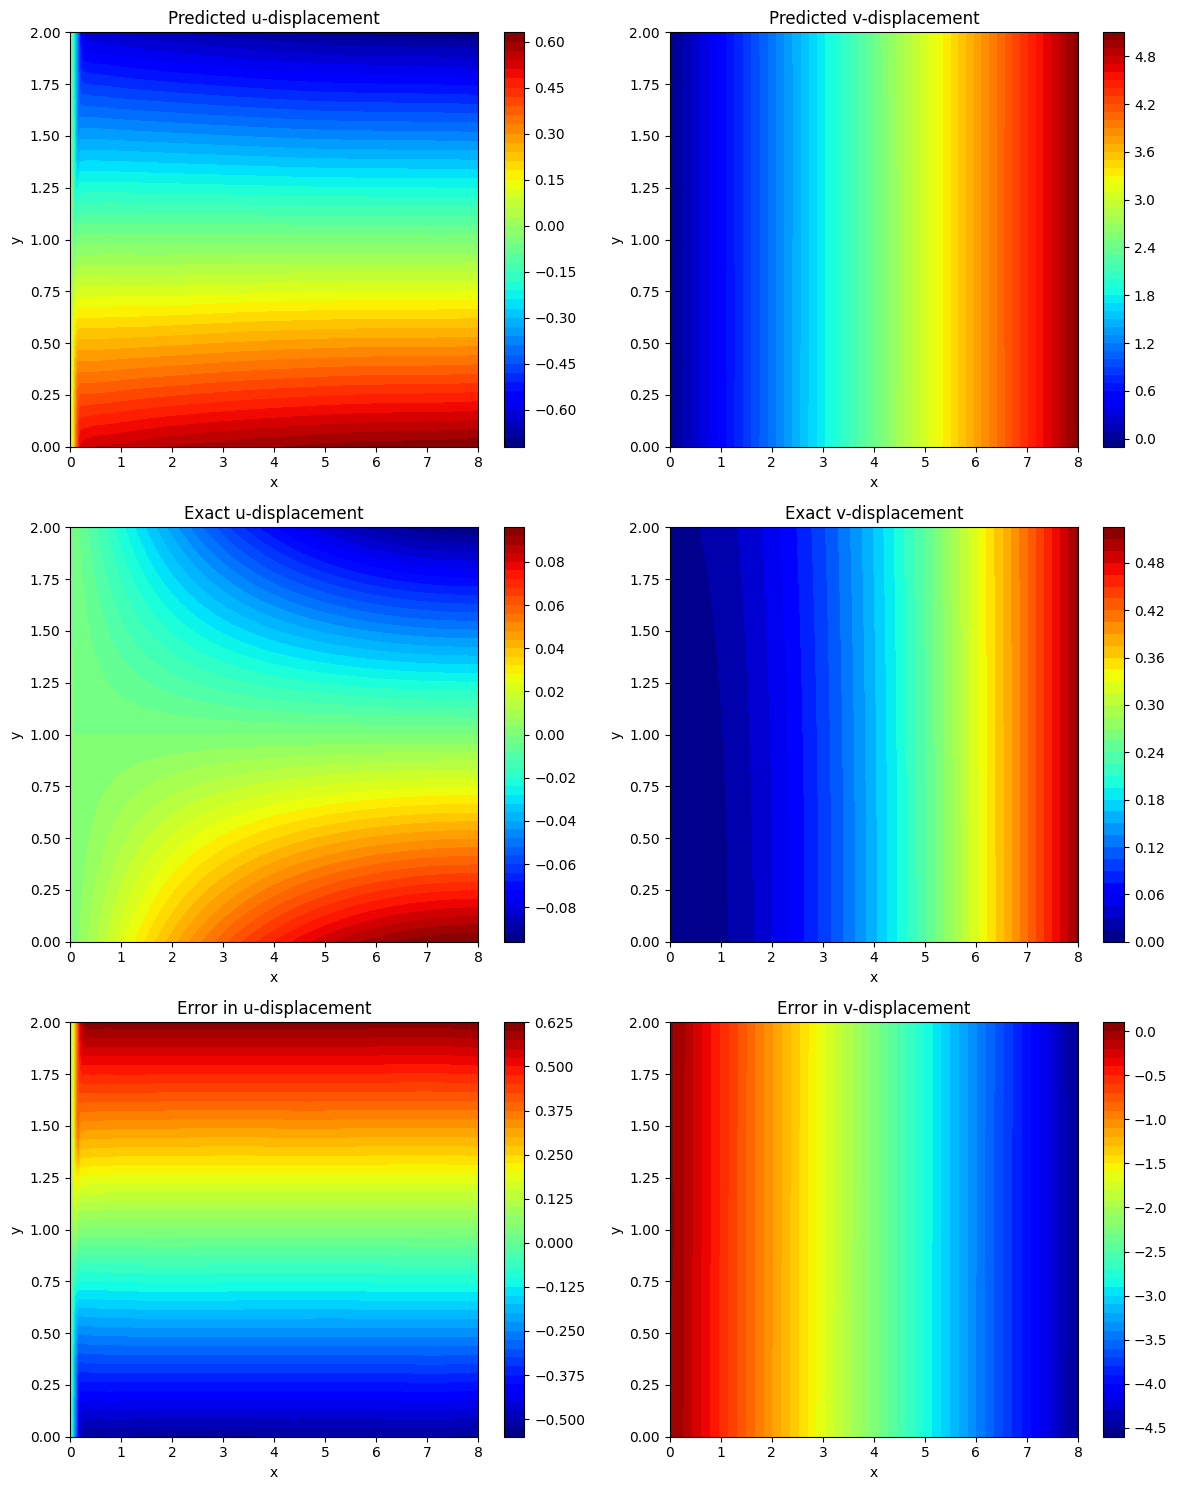

In [10]:
# Reshape data for plotting
U_pred_lr1 = u_pred_lr1.reshape(2*Ny, 2*Nx)
V_pred_lr1 = v_pred_lr1.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)
Error_U_lr1 = (U_exact - U_pred_lr1)
Error_V_lr1 = (V_exact - V_pred_lr1)

# Plotting the results
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred_lr1, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred_lr1, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U_lr1, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V_lr1, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

Learning rate 2: 5e-5

In [11]:
# 1. Learning rate of 5e-5
# Initialize model and move to device
model_lr2 = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model_lr2.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

learning2 = 5e-5
# 1. Training loop for learning rate = 1e-3
# First train with Adam
optimizer = optim.Adam(model_lr2.parameters(), lr=learning2)

num_epochs = 15000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model_lr2)
    energy.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}')
        
print("energy:", potential_energy(model_lr2).item())

Epoch [0/15000], Energy: 351.204293
Epoch [1000/15000], Energy: 1.216562
Epoch [2000/15000], Energy: 0.464862
Epoch [3000/15000], Energy: 0.197326
Epoch [4000/15000], Energy: 0.028304
Epoch [5000/15000], Energy: -0.102311
Epoch [6000/15000], Energy: -0.228664
Epoch [7000/15000], Energy: -0.319835
Epoch [8000/15000], Energy: -0.364484
Epoch [9000/15000], Energy: -0.388089
Epoch [10000/15000], Energy: -0.405814
Epoch [11000/15000], Energy: -0.420827
Epoch [12000/15000], Energy: -0.430933
Epoch [13000/15000], Energy: -0.436528
Epoch [14000/15000], Energy: -0.441557
energy: -0.4476439718943387


In [14]:
# 1. Testing the model for learning rate 1e-3
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred_lr2 = net_u(model_lr2, x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred_lr2 = net_v(model_lr2, x_test_tensor, y_test_tensor).cpu().detach().numpy()


def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u_lr2 = np.linalg.norm(u_exact_val - u_pred_lr2, 2) / np.linalg.norm(u_exact_val, 2)
error_v_lr2 = np.linalg.norm(v_exact_val - v_pred_lr2, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u for lr=5e-5: {error_u_lr2:e}')
print(f'Relative L2 error in v for lr=5e-5: {error_v_lr2:e}')

Relative L2 error in u for lr=5e-5: 7.498305e-02
Relative L2 error in v for lr=5e-5: 4.687161e-02


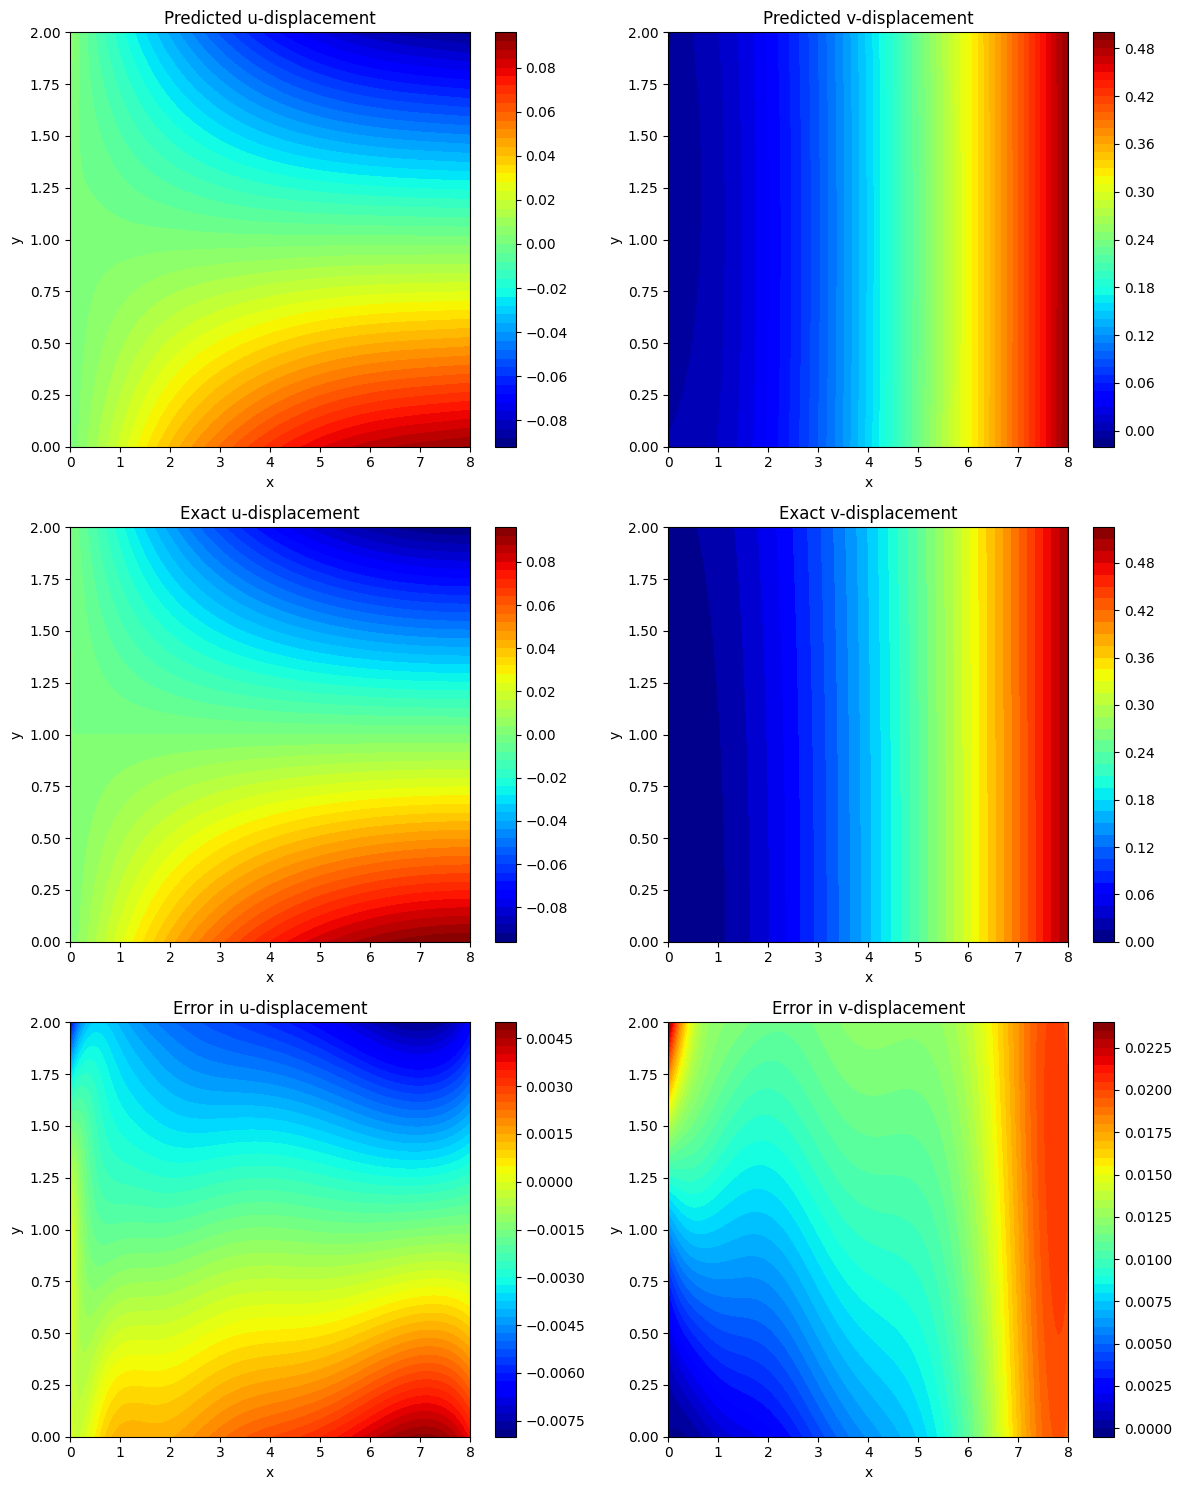

In [15]:
# Reshape data for plotting
U_pred_lr2 = u_pred_lr2.reshape(2*Ny, 2*Nx)
V_pred_lr2 = v_pred_lr2.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)
Error_U_lr2 = (U_exact - U_pred_lr2)
Error_V_lr2 = (V_exact - V_pred_lr2)

# Plotting the results
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred_lr2, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred_lr2, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U_lr2, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V_lr2, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

Learning rate 3: 1e-4 (baseline case)

See results from baseline from earlier

## Case 2: Strong BCs, Adam Followed by L-BFGS

**Objective:** test whether a second-order refinement stage reduces the error left over after Adam.

**Setup**
- BC enforcement: hard (trial functions)
- Stage 1: Adam for 10,000 epochs
- Stage 2: L-BFGS for 5,000 epochs
- Collocation grid: (80, 40)

**Tasks**
1. Train with Adam and record the error at epoch 10,000.
2. Continue with L-BFGS and record the error at the end of epoch 5,000.
3. Plot the combined loss history and mark the optimizer switch.

**Deliverables:** combined loss curve, error before and after L-BFGS, and a comparison to the Adam-only baseline.

In [17]:
# Adding L-BFGS with 5000 epochs
# Initialize model and move to device
model_BFGS = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model_BFGS.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

# Training loop
print("Initial energy:", potential_energy(model_BFGS).item())

# First train with Adam
optimizer = optim.Adam(model_BFGS.parameters(), lr=1e-4)

num_epochs = 10000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model_BFGS)
    energy.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}')
        
print("energy:", potential_energy(model_BFGS).item())

optimizer = optim.LBFGS(model_BFGS.parameters(), 
                        lr=1e-3,
                        max_iter=5000,
                        max_eval=6250, 
                        tolerance_grad=1e-7,
                        tolerance_change=1e-7,
                        history_size=50)

print('Starting L-BFGS optimization...')
optimizer.step(lambda: closure(model_BFGS))
print("Final energy:", potential_energy(model_BFGS).item())

Initial energy: 351.204292649702
Epoch [0/10000], Energy: 351.204293
Epoch [1000/10000], Energy: 0.510930
Epoch [2000/10000], Energy: 0.112625
Epoch [3000/10000], Energy: -0.077331
Epoch [4000/10000], Energy: -0.228140
Epoch [5000/10000], Energy: -0.327020
Epoch [6000/10000], Energy: -0.370402
Epoch [7000/10000], Energy: -0.392835
Epoch [8000/10000], Energy: -0.410193
Epoch [9000/10000], Energy: -0.424477
energy: -0.43326096529898717
Starting L-BFGS optimization...
Final energy: -0.43326339534274005


In [19]:
# Testing the model
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred_BFGS = net_u(model_BFGS, x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred_BFGS = net_v(model_BFGS, x_test_tensor, y_test_tensor).cpu().detach().numpy()


def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u_BFGS = np.linalg.norm(u_exact_val - u_pred_BFGS, 2) / np.linalg.norm(u_exact_val, 2)
error_v_BFGS = np.linalg.norm(v_exact_val - v_pred_BFGS, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u for L-BFGS: {error_u_BFGS:e}')
print(f'Relative L2 error in v for L-BFGS: {error_v_BFGS:e}')

Relative L2 error in u for L-BFGS: 8.994996e-02
Relative L2 error in v for L-BFGS: 6.500400e-02


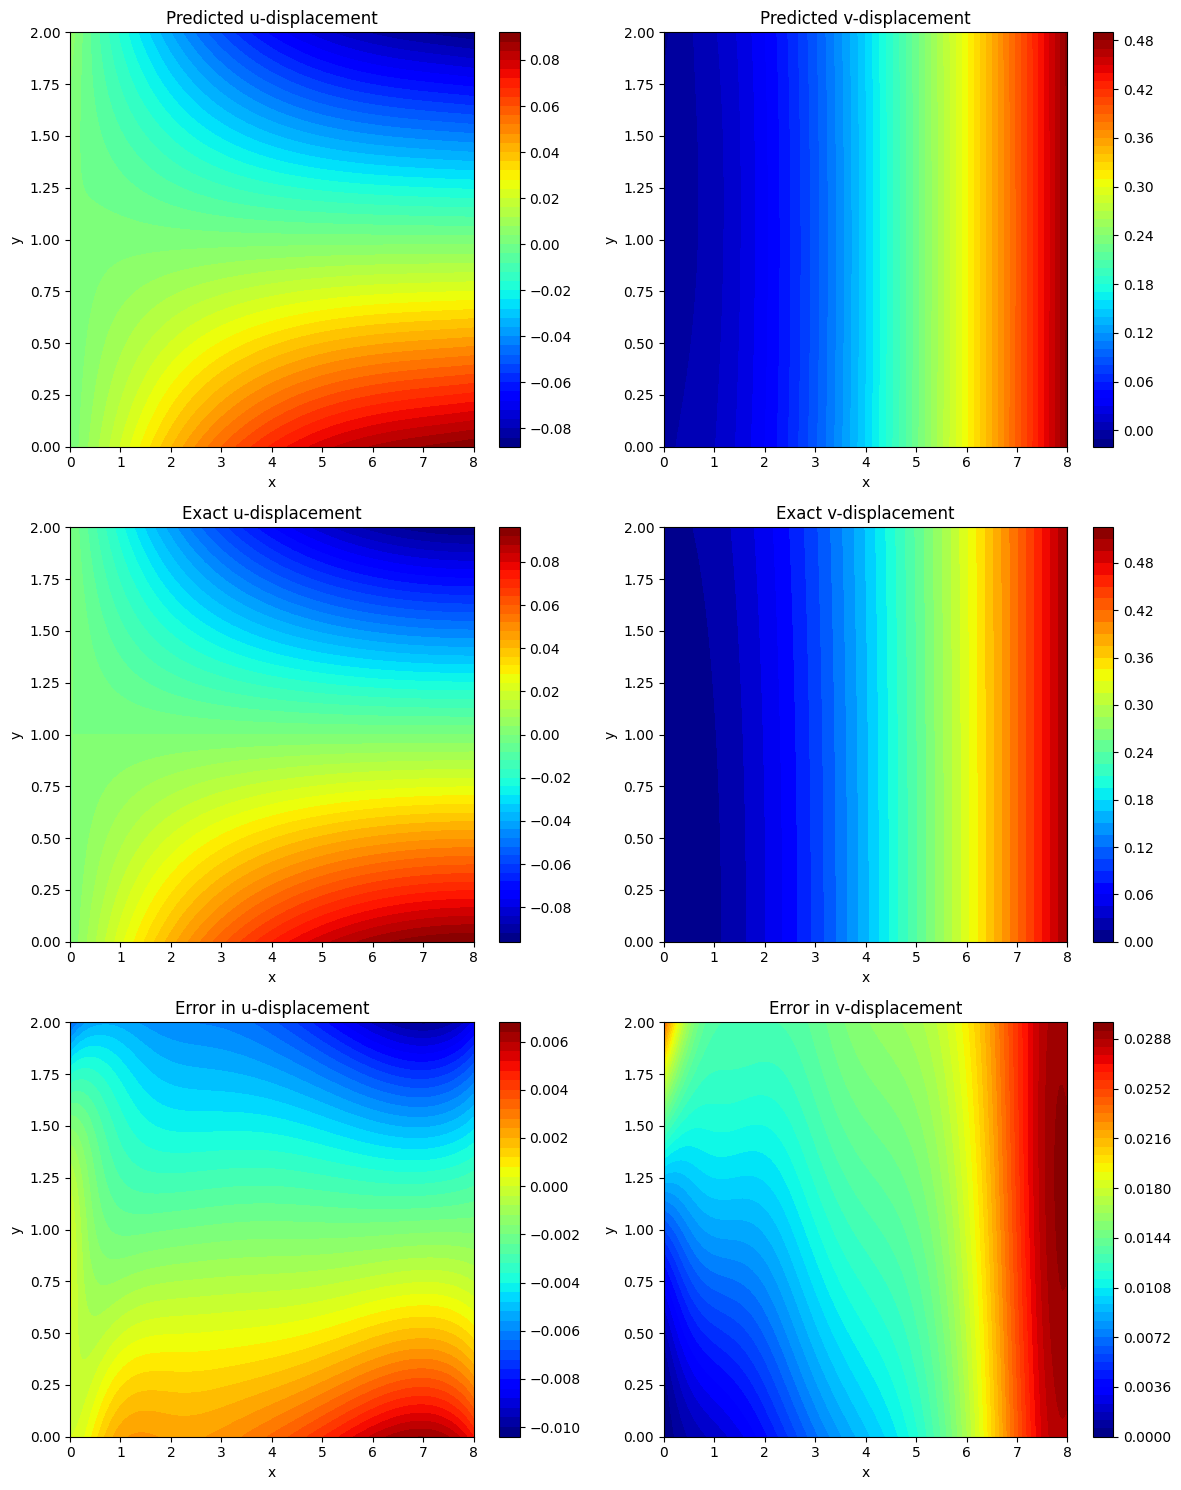

In [20]:
# Reshape data for plotting
U_pred_BFGS = u_pred_BFGS.reshape(2*Ny, 2*Nx)
V_pred_BFGS = v_pred_BFGS.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)
Error_U_BFGS = (U_exact - U_pred_BFGS)
Error_V_BFGS = (V_exact - V_pred_BFGS)

# Plotting the results
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred_BFGS, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred_BFGS, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U_BFGS, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V_BFGS, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

## Case 3: Strong BCs, Collocation Grid Study

**Objective:** measure how the number of collocation points affects accuracy and cost.

**Setup**
- BC enforcement: hard (trial functions)
- Optimizer: Adam, learning rate $1 \times 10^{-4}$
- Grids: (120, 60) and (80, 40) (baseline)

**Tasks**
1. Train one model per grid with identical hyperparameters.
2. Compare the relative L2 error and training time for each grid.
3. Plot the pointwise error field for each grid.

**Deliverables:** error table with training time, error contour plots, and a short note on whether the added points justify the added cost.

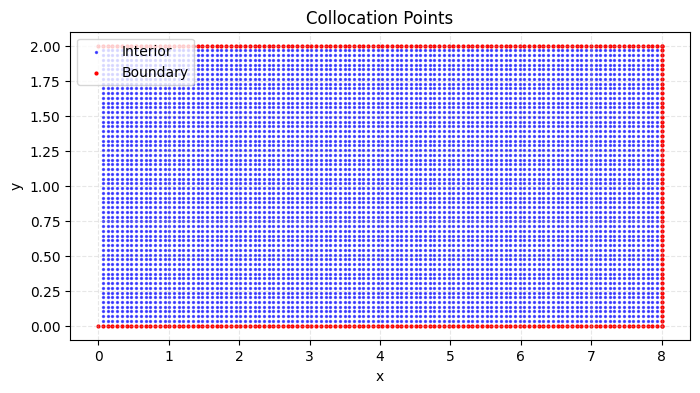

In [23]:
# Set default tensor type and device
torch.set_default_dtype(torch.float64)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Check if MPS is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')    

# Material and geometric parameters
E = 1e3           # Young's modulus
nu = 0.25         # Poisson's ratio
P = 2.0           # Applied load
L = 8.0           # Length of the beam
W = 2.0           # Width of the beam
b = 1.0           # Depth of the beam
I = b * W**3 / 12.0   # Moment of inertia
lambda_ = E * nu / ((1 + nu)*(1 - 2*nu))  # Lamé's first parameter
mu = E / (2*(1 + nu))  # Lamé's second parameter (shear modulus)

# Generate interior collocation points (excluding x=0)
Nx, Ny = 120, 60  # Original grid size
x = np.linspace(0, L, Nx)[1:]  # Exclude x=0 point
y = np.linspace(0, W, Ny)[1:-1]  # Exclude top and bottom boundaries
X, Y = np.meshgrid(x, y)
X_star = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

# Generate boundary points
# Right boundary (x = L)
y_right = np.linspace(0, W, Ny)
x_right = L * np.ones_like(y_right)
X_right = np.hstack((x_right[:, None], y_right[:, None]))

# Top boundary (y = W/2)
x_top = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
y_top = (W) * np.ones_like(x_top)
X_top = np.hstack((x_top[:, None], y_top[:, None]))

# Bottom boundary (y = -W/2)
x_bottom = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
y_bottom =  0 * np.ones_like(x_bottom) #(-W/2)
X_bottom = np.hstack((x_bottom[:, None], y_bottom[:, None]))

# Combine all boundary points
X_boundary = np.vstack((X_right, X_top, X_bottom))

# Convert to torch tensors
x_collocation = torch.tensor(X_star[:, 0:1], requires_grad=True, device=device)
y_collocation = torch.tensor(X_star[:, 1:2], requires_grad=True, device=device)

x_boundary_tensor = torch.tensor(X_boundary[:, 0:1], requires_grad=True, device=device)
y_boundary_tensor = torch.tensor(X_boundary[:, 1:2], requires_grad=True, device=device)

# Plot collocation points
plt.figure(figsize=(8, 4))

# Interior points (blue)
plt.scatter(X_star[:, 0], X_star[:, 1], c='blue', s=2, alpha=0.6, label='Interior')

# Boundary points (red)
plt.scatter(X_boundary[:, 0], X_boundary[:, 1], c='red', s=4, label='Boundary')

plt.title('Collocation Points')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()


Initial energy: 348.9306875624905
Epoch [0/15000], Energy: 348.930688
Epoch [1000/15000], Energy: 0.517495
Epoch [2000/15000], Energy: 0.113878
Epoch [3000/15000], Energy: -0.073760
Epoch [4000/15000], Energy: -0.221836
Epoch [5000/15000], Energy: -0.317864
Epoch [6000/15000], Energy: -0.359456
Epoch [7000/15000], Energy: -0.380974
Epoch [8000/15000], Energy: -0.397767
Epoch [9000/15000], Energy: -0.411750
Epoch [10000/15000], Energy: -0.420215
Epoch [11000/15000], Energy: -0.424768
Epoch [12000/15000], Energy: -0.428908
Epoch [13000/15000], Energy: -0.433168
Epoch [14000/15000], Energy: -0.437644
energy: -0.4407057438319977
Relative L2 error in u: 8.771993e-02
Relative L2 error in v: 6.043773e-02


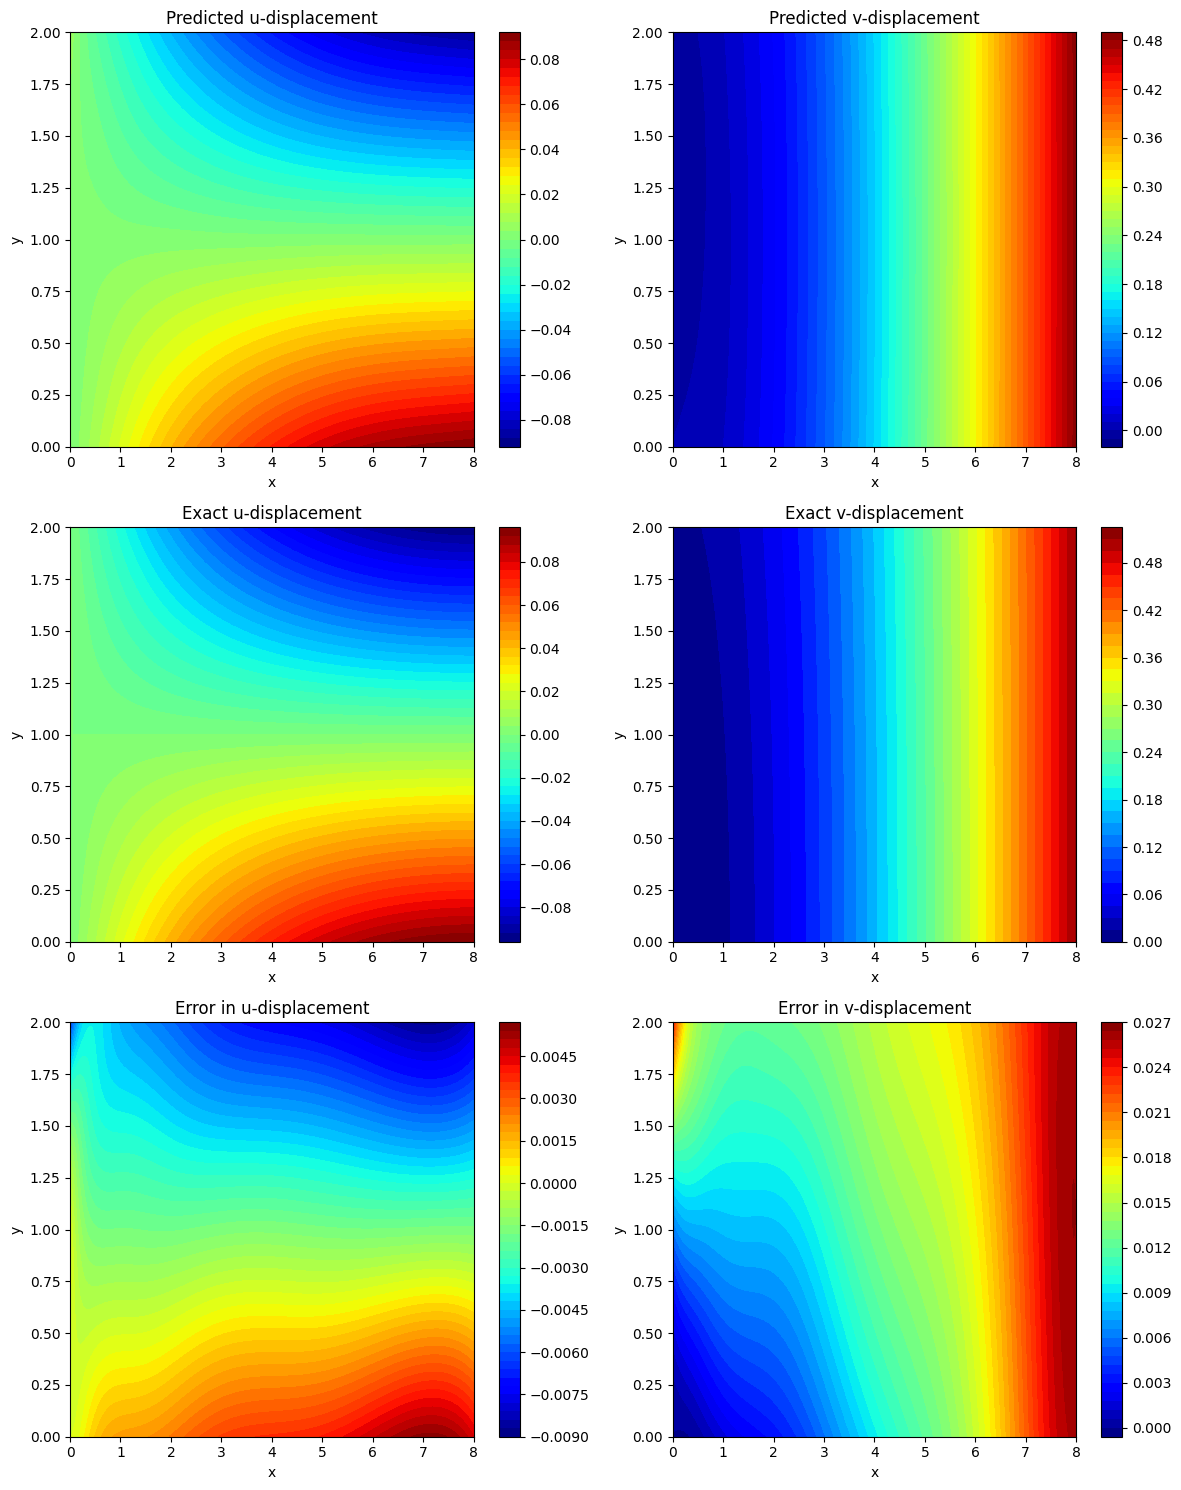

In [24]:
# Initialize model and move to device
model_grid = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model_grid.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

print("Initial energy:", potential_energy(model_grid).item())

# First train with Adam
optimizer = optim.Adam(model_grid.parameters(), lr=1e-4)

num_epochs = 15000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model_grid)
    energy.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}')
        
print("energy:", potential_energy(model_grid).item())
# Testing the model
# Keeping the test set fixed!
x_test = np.linspace(0, L, 160)
y_test = np.linspace(0, W, 80)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred_grid = net_u(model_grid, x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred_grid = net_v(model_grid, x_test_tensor, y_test_tensor).cpu().detach().numpy()

def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u = np.linalg.norm(u_exact_val - u_pred_grid, 2) / np.linalg.norm(u_exact_val, 2)
error_v = np.linalg.norm(v_exact_val - v_pred_grid, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u: {error_u:e}')
print(f'Relative L2 error in v: {error_v:e}')

# Reshape data for plotting
U_pred_grid = u_pred_grid.reshape(80, 160)
V_pred_grid = v_pred_grid.reshape(80, 160)
U_exact = u_exact_val.reshape(80, 160)
V_exact = v_exact_val.reshape(80, 160)
Error_U_grid = (U_exact - U_pred_grid)
Error_V_grid = (V_exact - V_pred_grid)

# Plotting the results
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred_grid, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred_grid, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U_grid, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V_grid, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

## Case 4: Soft BCs with Adaptive Weights

**Objective:** test whether penalty-based BC enforcement with adaptive loss weights can match or beat hard enforcement.

**Setup**
- BC enforcement: soft, through penalty terms in the loss
- Loss: $\mathcal{L} = \Pi(\theta) + \lambda_{bc}(t) \, \mathcal{L}_{bc}(\theta)$
- Weight update: adaptive $\lambda_{bc}(t)$ (describe the scheme used, e.g., gradient-norm balancing)
- Optimizer: Adam, learning rate $1 \times 10^{-4}$
- Collocation grid: (80, 40)

**Tasks**
1. Implement the soft BC loss and the adaptive weight update.
2. Plot the loss components and $\lambda_{bc}$ over training.
3. Report the BC violation at the clamped edge along with the relative L2 error.

**Deliverables:** weight history, BC violation, error table, and a comparison to hard enforcement.

Initial energy: 659.9029742638903
Epoch [0/15000], Energy: 659.902974, BC loss: 3.792e-01, lambda_bc: 1.272e+04
Epoch [1000/15000], Energy: 24.475107, BC loss: 2.931e-07, lambda_bc: 8.920e+08
Epoch [2000/15000], Energy: 4.427122, BC loss: 2.088e-07, lambda_bc: 3.594e+08
Epoch [3000/15000], Energy: 1.868228, BC loss: 1.706e-07, lambda_bc: 1.285e+08
Epoch [4000/15000], Energy: 1.271913, BC loss: 1.484e-07, lambda_bc: 7.908e+07
Epoch [5000/15000], Energy: 0.937145, BC loss: 1.229e-07, lambda_bc: 8.587e+07
Epoch [6000/15000], Energy: 0.713529, BC loss: 8.955e-08, lambda_bc: 9.216e+07
Epoch [7000/15000], Energy: 0.560204, BC loss: 5.526e-08, lambda_bc: 9.824e+07
Epoch [8000/15000], Energy: 0.459522, BC loss: 3.645e-08, lambda_bc: 8.702e+07
Epoch [9000/15000], Energy: 0.371572, BC loss: 2.518e-08, lambda_bc: 9.599e+07
Epoch [10000/15000], Energy: 0.238325, BC loss: 1.988e-08, lambda_bc: 1.201e+08
Epoch [11000/15000], Energy: 0.170109, BC loss: 1.703e-08, lambda_bc: 1.644e+07
Epoch [12000/150

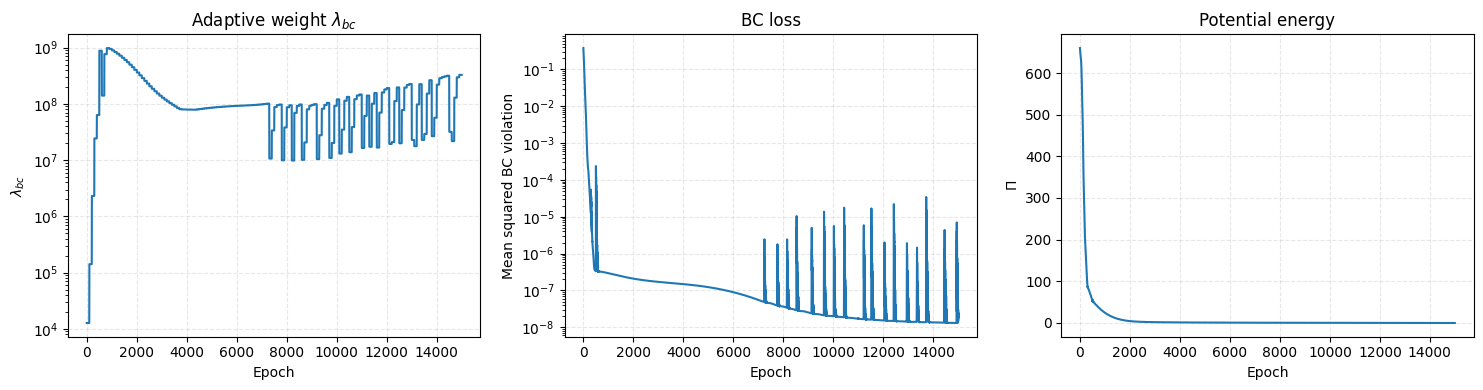

In [25]:
Nx, Ny = 80, 40 
x = np.linspace(0, L, Nx)[1:]
y = np.linspace(0, W, Ny)[1:-1]
X, Y = np.meshgrid(x, y)
X_star = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

y_right = np.linspace(0, W, Ny)
x_right = L * np.ones_like(y_right)
X_right = np.hstack((x_right[:, None], y_right[:, None]))

x_top = np.linspace(0, L, Nx)
y_top = (W) * np.ones_like(x_top)
X_top = np.hstack((x_top[:, None], y_top[:, None]))

x_bottom = np.linspace(0, L, Nx)
y_bottom = 0 * np.ones_like(x_bottom)
X_bottom = np.hstack((x_bottom[:, None], y_bottom[:, None]))

X_boundary = np.vstack((X_right, X_top, X_bottom))

x_collocation = torch.tensor(X_star[:, 0:1], requires_grad=True, device=device)
y_collocation = torch.tensor(X_star[:, 1:2], requires_grad=True, device=device)
x_boundary_tensor = torch.tensor(X_boundary[:, 0:1], requires_grad=True, device=device)
y_boundary_tensor = torch.tensor(X_boundary[:, 1:2], requires_grad=True, device=device)

torch.manual_seed(42)  
model_soft = Net().to(device) 
torch.manual_seed(42)
for m in model_soft.layers: 
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

y_bc = np.linspace(0, W, Ny)[:, None]  
x_bc = np.zeros_like(y_bc)  
x_bc_tensor = torch.tensor(x_bc, device=device) 
y_bc_tensor = torch.tensor(y_bc, device=device) 

def g_u(y):  
    return (P * y) / (6 * E * I) * ((2 + nu) * (y**2 - W**2/4))  # ADDED

def g_v(y):  
    return -(P) / (6 * E * I) * (3 * nu * y**2 * L)  # ADDED

def net_u(model, x, y):
    u_NN, _ = model(x, y)
    return u_NN 

def net_v(model, x, y):
    _, v_NN = model(x, y)
    return v_NN  

def bc_loss(model):  
    u_bc = net_u(model, x_bc_tensor, y_bc_tensor)  
    v_bc = net_v(model, x_bc_tensor, y_bc_tensor)  
    return torch.mean((u_bc - g_u(y_bc_tensor))**2 + (v_bc - g_v(y_bc_tensor))**2)  

print("Initial energy:", potential_energy(model_soft).item())  

# First train with Adam
optimizer = optim.Adam(model_soft.parameters(), lr=1e-4) 

params = list(model_soft.parameters()) 
lambda_bc = 1.0  # initial BC weight
alpha = 0.9  # moving-average factor for the weight update
update_every = 100  # update the weight every 100 epochs
lambda_history = []  # for plotting the weight over training
bc_history = []  # for plotting BC violation over training
energy_history = []  # for plotting the energy over training

num_epochs = 15000
for epoch in range(num_epochs):
    optimizer.zero_grad()
    energy = potential_energy(model_soft)  
    loss_bc = bc_loss(model_soft)  

    if epoch % update_every == 0:  # gradient-norm balancing
        g_pi = torch.autograd.grad(energy, params, retain_graph=True)  
        g_bc = torch.autograd.grad(loss_bc, params, retain_graph=True)  
        max_pi = max(g.abs().max() for g in g_pi)  # max |grad of energy|
        mean_bc = torch.cat([g.abs().flatten() for g in g_bc]).mean()  # mean |grad of BC loss|
        lambda_hat = (max_pi / (mean_bc + 1e-12)).item() 
        lambda_bc = (1 - alpha) * lambda_bc + alpha * lambda_hat  # smoothed update

    loss = energy + lambda_bc * loss_bc  # total loss
    loss.backward()  
    optimizer.step()

    lambda_history.append(lambda_bc)  
    bc_history.append(loss_bc.item()) 
    energy_history.append(energy.item())

    if epoch % 1000 == 0:
        print(f'Epoch [{epoch}/{num_epochs}], Energy: {energy.item():.6f}, BC loss: {loss_bc.item():.3e}, lambda_bc: {lambda_bc:.3e}') 

print("energy:", potential_energy(model_soft).item())  
print("Max BC violation (u, v):", (net_u(model_soft, x_bc_tensor, y_bc_tensor) - g_u(y_bc_tensor)).abs().max().item(),
      (net_v(model_soft, x_bc_tensor, y_bc_tensor) - g_v(y_bc_tensor)).abs().max().item())

# Training history: adaptive weight, BC loss, and energy
fig, ax = plt.subplots(1, 3, figsize=(15, 4))  
ax[0].semilogy(lambda_history)  # adaptive BC weight
ax[0].set_title('Adaptive weight $\\lambda_{bc}$')  
ax[0].set_xlabel('Epoch')  
ax[0].set_ylabel('$\\lambda_{bc}$')  
ax[0].grid(True, linestyle='--', alpha=0.3)  

ax[1].semilogy(bc_history)  # BC penalty term
ax[1].set_title('BC loss')  
ax[1].set_xlabel('Epoch')  
ax[1].set_ylabel('Mean squared BC violation')  
ax[1].grid(True, linestyle='--', alpha=0.3)  

ax[2].plot(energy_history)  # potential energy
ax[2].set_title('Potential energy')  
ax[2].set_xlabel('Epoch')  
ax[2].set_ylabel('$\\Pi$')  
ax[2].grid(True, linestyle='--', alpha=0.3)  

plt.tight_layout()  
plt.show() 

Relative L2 error in u: 6.605679e-01
Relative L2 error in v: 6.435668e-01


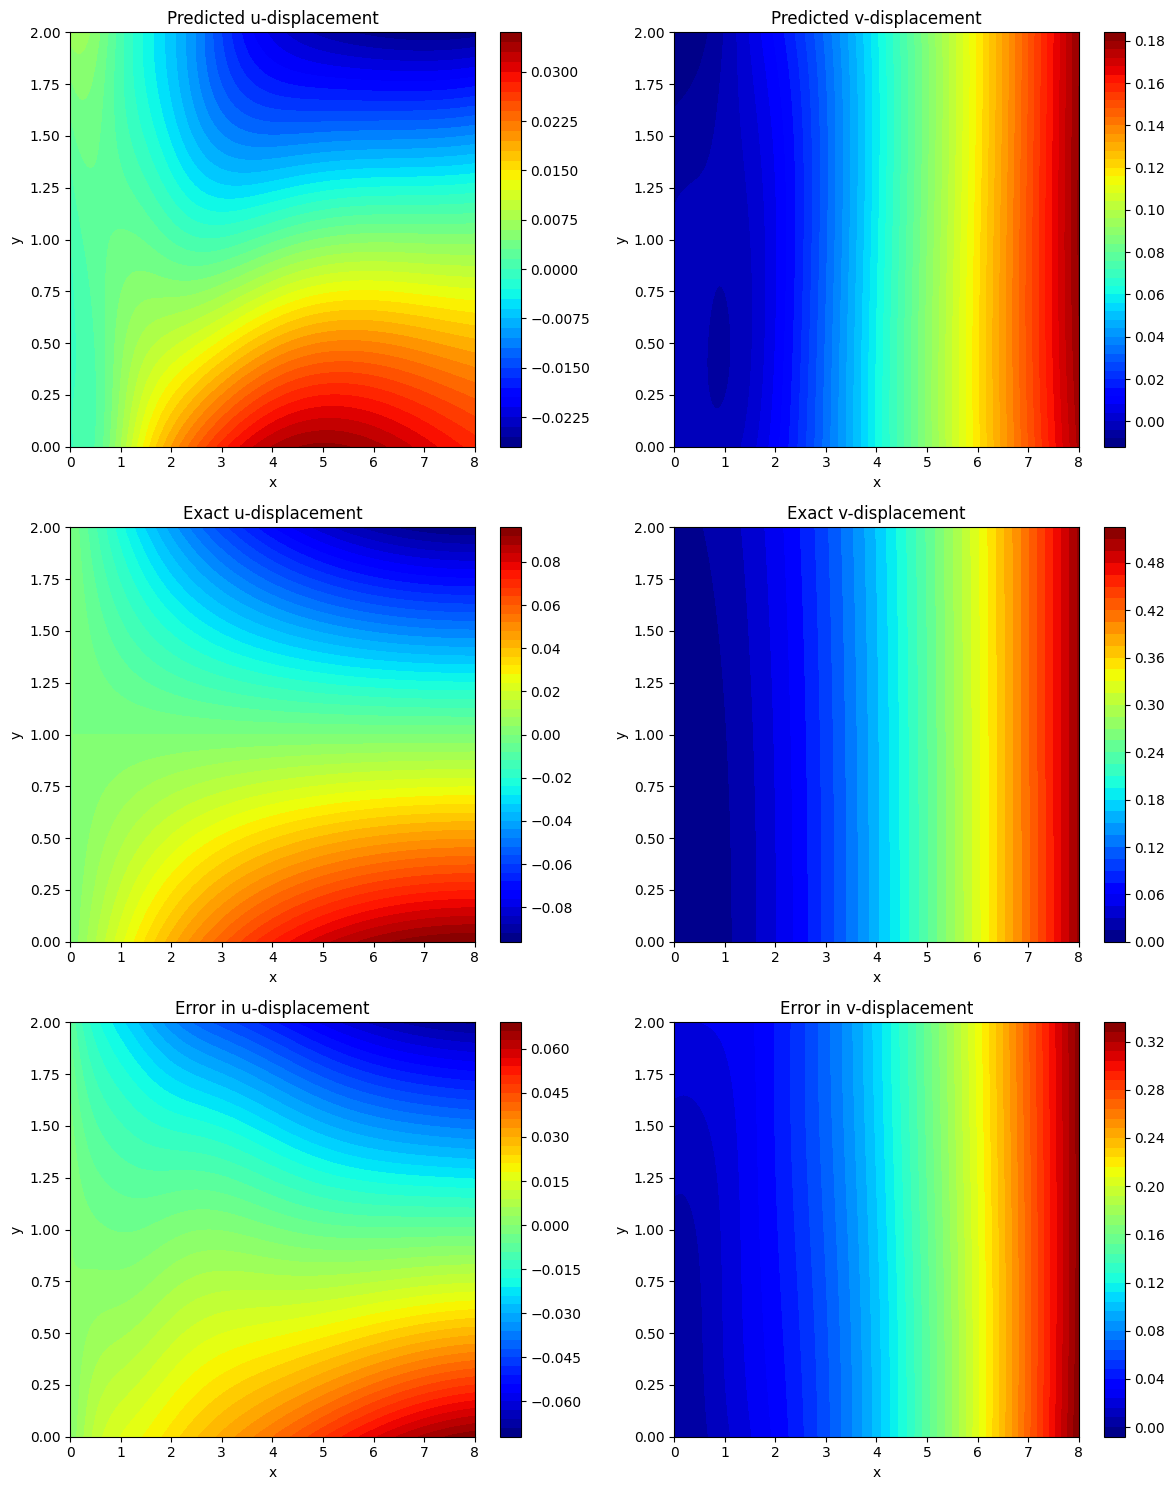

In [26]:
# Testing the model
x_test = np.linspace(0, L, 2*Nx)  
y_test = np.linspace(0, W, 2*Ny)  
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

u_pred_soft = net_u(model_soft, x_test_tensor, y_test_tensor).cpu().detach().numpy()  
v_pred_soft = net_v(model_soft, x_test_tensor, y_test_tensor).cpu().detach().numpy()  

def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4) 
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])

error_u_soft = np.linalg.norm(u_exact_val - u_pred_soft, 2) / np.linalg.norm(u_exact_val, 2)
error_v_soft = np.linalg.norm(v_exact_val - v_pred_soft, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u: {error_u_soft:e}')
print(f'Relative L2 error in v: {error_v_soft:e}')

U_pred_soft = u_pred_soft.reshape(2*Ny, 2*Nx)
V_pred_soft = v_pred_soft.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)  
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)  
Error_U_soft = (U_exact - U_pred_soft)
Error_V_soft = (V_exact - V_pred_soft)

fig, ax = plt.subplots(3, 2, figsize=(12, 15))

cf = ax[0, 0].contourf(X_test, Y_test, U_pred_soft, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred_soft, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

cf = ax[2, 0].contourf(X_test, Y_test, Error_U_soft, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V_soft, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

## Summary and Comparison

| Case | Configuration | Rel. L2 (closed-form) | Rel. L2 (baseline) | Beats $2.4 \times 10^{-3}$? |
|---|---|---|---|---|
| Baseline | Hard BC, Adam $1 \times 10^{-4}$, (80, 40) | | | |
| 1a | Hard BC, lr $1 \times 10^{-3}$ | | | |
| 1b | Hard BC, lr $5 \times 10^{-5}$ | | | |
| 2 | Hard BC, Adam + L-BFGS | | | |
| 3 | Hard BC, grid (120, 60) | | | |
| 4 | Soft BC, adaptive weights | | | |

**Conclusion:** state which approach gives the lowest error, by how much it improves on the baseline, and what it costs in training time.